# EDA: вердикты судьи на 4 курсе

Что здесь: состав, объём и качество данных проверки студенческих работ судьёй на потоке 4 курса
«Системы ИИ», срез на 1 ноября 2026 года. Цель анализа: понять, на каких данных можно мерить судью
и что мешает это делать.

Таблицы лежат в `data/eda/` и обезличены скриптом `scripts/anonymize_eda.py`: вместо команд номера,
вместо дат недели курса, отметок приёмки по командам нет. Описание полей: `data/eda/README.md`.
Сами работы и обоснования судьи в репозиторий не попадают.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path("..") if Path("../data/eda").exists() else Path()
DATA = ROOT / "data" / "eda"
# Картинки отдельно: отчёт reports/eda.md читают прямо на GitHub
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#6b6b68", "#e6e5e1"
SERIES = "#2a78d6"
STATES = {"closed": "#0ca30c", "open": "#d03b3b", "unsure": "#fab219"}
NAMES = {"closed": "закрыт", "open": "не закрыт", "unsure": "не уверен"}
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "font.size": 11,
        "axes.edgecolor": GRID,
        "axes.labelcolor": MUTED,
        "text.color": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": GRID,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlelocation": "left",
        "axes.titlesize": 13,
        "figure.dpi": 110,
    }
)

verdicts = pd.read_csv(DATA / "verdicts.csv")
runs = pd.read_csv(DATA / "runs.csv")
reviews = pd.read_csv(DATA / "reviews.csv")
questions = pd.read_csv(DATA / "questions_summary.csv")
rechecks = pd.read_csv(DATA / "rechecks_summary.csv")
data = verdicts.merge(
    runs[["run", "trigger", "agent", "status", "week"]], on="run", how="left"
)
new = data[data["agent"] == "0.1.0"].copy()
new_runs = runs[(runs["agent"] == "0.1.0") & (runs["status"] == "done")]

## 1. Состав и объём

In [2]:
pd.DataFrame(
    {
        "значение": [
            verdicts["team"].nunique(),
            verdicts["work"].nunique(),
            verdicts["criterion"].nunique(),
            len(runs),
            len(new_runs),
            len(verdicts),
            len(new),
            len(reviews),
        ]
    },
    index=[
        "команд",
        "работ",
        "критериев",
        "прогонов всего",
        "готовых прогонов нового судьи",
        "вердиктов всего",
        "вердиктов нового судьи",
        "закрытых приёмок",
    ],
)

,значение
команд,8
работ,6
критериев,82
прогонов всего,156
готовых прогонов нового судьи,104
вердиктов всего,493
вердиктов нового судьи,349
закрытых приёмок,25


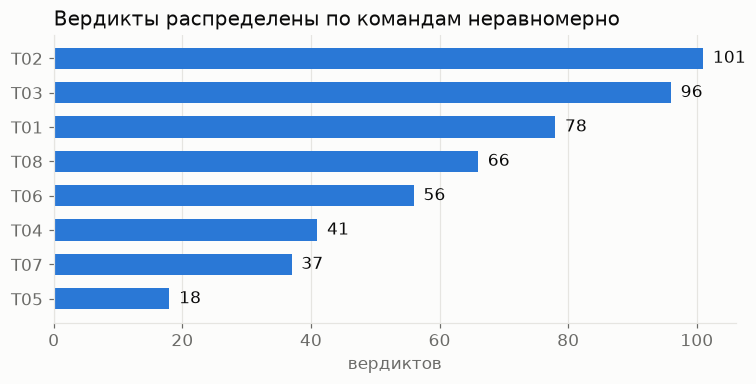

In [3]:
by_team = verdicts.groupby("team").size().sort_values()
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(by_team.index, by_team.values, color=SERIES, height=0.62)
for y, value in enumerate(by_team.values):
    ax.text(value + 1.5, y, str(value), va="center", color=INK)
ax.set_title("Вердикты распределены по командам неравномерно")
ax.set_xlabel("вердиктов")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "01_verdicts_by_team.png", dpi=150, bbox_inches="tight")
plt.show()

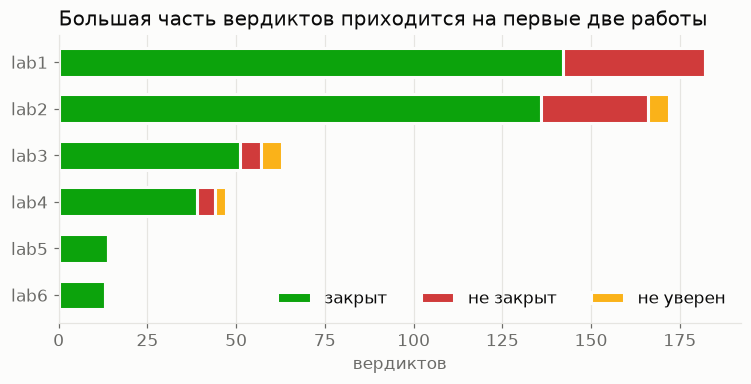

In [4]:
table = verdicts.groupby(["work", "state"]).size().unstack(fill_value=0)[list(STATES)]
fig, ax = plt.subplots(figsize=(8, 3.4))
left = pd.Series(0, index=table.index)
for state, color in STATES.items():
    ax.barh(
        table.index,
        table[state],
        left=left,
        color=color,
        height=0.62,
        label=NAMES[state],
        edgecolor=SURFACE,
        linewidth=2,
    )
    left = left + table[state]
ax.invert_yaxis()
ax.set_title("Большая часть вердиктов приходится на первые две работы")
ax.set_xlabel("вердиктов")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, ncols=3, loc="lower right")
fig.savefig(FIG / "02_states_by_work.png", dpi=150, bbox_inches="tight")
plt.show()

**Вывод.** Данных немного: 8 команд, 6 работ, 82 критерия, 493 вердикта, из них 349 от нового судьи. Вердикты зависят друг от друга внутри команды, поэтому настоящий размер выборки ближе к восьми, чем к пятистам. Самая крупная команда дала в 5,6 раза больше вердиктов, чем самая мелкая, а на первые две работы приходится 72% вердиктов. Значит, эталон надо отбирать с разбивкой по командам и работам, а части выборки делить по командам.

## 2. Качество данных

In [5]:
pd.DataFrame(
    {
        "значение": [
            (runs["trigger"] == "import").sum(),
            verdicts["check_type"].isna().sum(),
            (runs["status"] == "failed").sum(),
            runs["agent"].dropna().nunique(),
            int(reviews["minutes"].max()),
            int(questions.loc[questions["dispute"] != "none", "count"].sum()),
        ]
    },
    index=[
        "прогонов перенесено со старой платформы",
        "вердиктов без типа проверки",
        "упавших прогонов",
        "разных версий в поле agent",
        "самая длинная приёмка, минут",
        "отметок «агент ошибся» на потоке",
    ],
)

,значение
прогонов перенесено со старой платформы,50
вердиктов без типа проверки,144
упавших прогонов,2
разных версий в поле agent,2
"самая длинная приёмка, минут",5263
отметок «агент ошибся» на потоке,0


In [6]:
print(verdicts.isna().mean().round(3)[lambda s: s > 0].to_string())
print()
print("вердиктов нового судьи без типа проверки:", new["check_type"].isna().sum())
print("повторов строк:", verdicts.duplicated().sum())

check_type        0.292
answers           0.588
evidence_kinds    0.181

вердиктов нового судьи без типа проверки: 0
повторов строк: 0


**Вывод.** Дублей нет, но смешаны две версии. 50 прогонов перенесены со старой платформы: у них нет типа проверки и настоящего времени, поэтому дальше считаем только нового судью. Поле версии у всех новых прогонов одно, `0.1.0`, хотя подсказки менялись, значит версии можно различить только по неделям. Ответы модели записаны не у всех вердиктов, поэтому голосование считаем на части данных. У одной приёмки таймер показывает 5263 минуты, поэтому для времени берём медиану. Главная проблема: отметок «агент ошибся» на потоке нет, так что качество нельзя посчитать без разметки.

## 3. Что отвечает судья

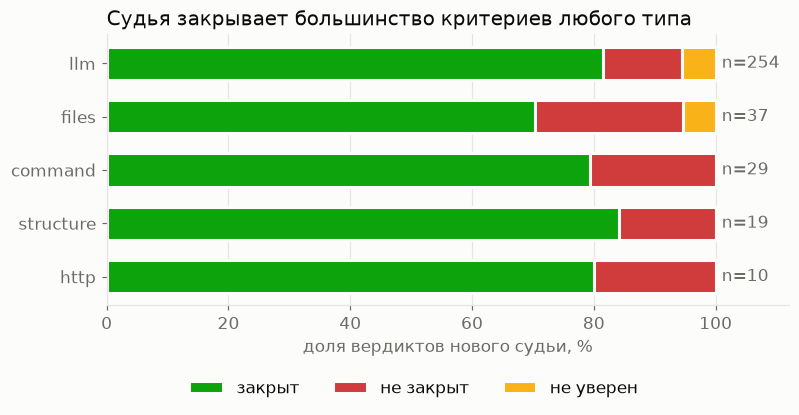

,вердиктов,доля
state,,
closed,280,0.802
open,53,0.152
unsure,16,0.046


In [7]:
share = (
    new.groupby(["check_type", "state"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=list(STATES), fill_value=0)
)
share = share.loc[share.sum(axis=1).sort_values().index]
parts = share.div(share.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(8, 3.2))
left = pd.Series(0.0, index=parts.index)
for state, color in STATES.items():
    ax.barh(
        parts.index,
        parts[state],
        left=left,
        color=color,
        height=0.62,
        label=NAMES[state],
        edgecolor=SURFACE,
        linewidth=2,
    )
    left = left + parts[state]
for y, name in enumerate(parts.index):
    ax.text(101, y, f"n={share.loc[name].sum()}", va="center", color=MUTED)
ax.set_xlim(0, 112)
ax.set_title("Судья закрывает большинство критериев любого типа")
ax.set_xlabel("доля вердиктов нового судьи, %")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, ncols=3, loc="upper center", bbox_to_anchor=(0.45, -0.22))
fig.savefig(FIG / "03_states_by_check_type.png", dpi=150, bbox_inches="tight")
plt.show()
new["state"].value_counts().to_frame("вердиктов").assign(
    доля=lambda d: (d["вердиктов"] / len(new)).round(3)
)

In [8]:
top = (
    new[new["state"] != "closed"]
    .groupby("criterion")
    .size()
    .sort_values(ascending=False)
    .head(8)
)
closed_rate = (
    new.groupby("criterion")["state"].apply(lambda s: (s == "closed").mean()).round(2)
)
pd.DataFrame({"не закрытых и сомнений": top, "доля закрытых": closed_rate[top.index]})

,не закрытых и сомнений,доля закрытых
criterion,,
lab2-erd-api,9,0.44
lab1-research-sources,8,0.00
lab2-golden-dataset,7,0.42
lab4-burndown,4,0.20
lab2-compose-dev,4,0.60
lab2-spike-notes,3,0.81
lab2-adr-price,3,0.70
lab3-e2e,3,0.40


**Вывод.** Новый судья закрывает 80% критериев, не закрывает 15% и сомневается в 5%, покрытие 95%. Доля закрытых близка у всех типов проверки, ниже всего у `files`, но там всего 37 вердиктов. Невыполненных критериев мало, поэтому общая точность бесполезна: судья, закрывающий всё, получил бы около 80%. Нужны отдельные доли ложных «закрыто» и ложных «не закрыт». Трудные критерии сосредоточены в ресёрче, ERD и golden dataset, их стоит взять в эталон с запасом.

## 4. Откуда берётся «не уверен» и насколько судья стабилен

In [9]:
voted = new[new["answers"].notna()].copy()
voted["unanimous"] = ~voted["votes_split"]
unsure = new[new["state"] == "unsure"]
chains = new.groupby(["team", "role", "criterion"])["state"].agg(["nunique", "size"])
repeated = chains[chains["size"] > 1]
pd.DataFrame(
    {
        "значение": [
            len(voted),
            round(voted["votes_split"].mean(), 3),
            len(unsure),
            int((unsure["answers"].notna() & ~unsure["votes_split"]).sum()),
            len(repeated),
            round((repeated["nunique"] > 1).mean(), 3),
        ]
    },
    index=[
        "вердиктов с записанными ответами",
        "доля вердиктов, где ответы модели разошлись",
        "вердиктов «не уверен»",
        "из них при единогласных ответах модели",
        "критериев, проверенных больше одного раза",
        "доля таких критериев, где итог менялся",
    ],
)

,значение
вердиктов с записанными ответами,203.000
"доля вердиктов, где ответы модели разошлись",0.074
вердиктов «не уверен»,16.000
из них при единогласных ответах модели,11.000
"критериев, проверенных больше одного раза",93.000
"доля таких критериев, где итог менялся",0.430


**Вывод.** Ответы модели расходятся редко, в 7,4% вердиктов с записанными ответами. Но 11 из 16 «не уверен» возникли при единогласных ответах: вердикт снимали правила судьи, а не сомнения модели. Значит, покрытие зависит от правил не меньше, чем от модели. У 43% критериев, проверенных несколько раз, итог менялся, но сюда входят и доработки студентов. Настоящую повторяемость надо мерить отдельными прогонами на одном коммите.

## 5. Что видели люди

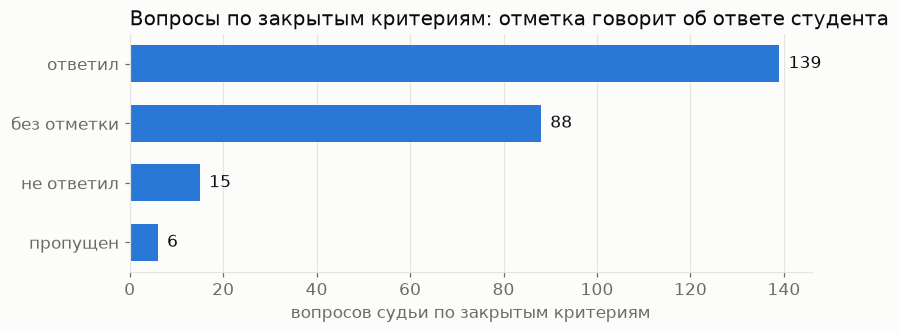

закрытых вердиктов: 395, из них с вопросом к приёмке: 226
source
agent        451
criterion    183
own            5
promise       26


In [10]:
closed_total = (verdicts["state"] == "closed").sum()
closed_question = ((verdicts["state"] == "closed") & verdicts["has_question"]).sum()
marks = questions[
    (questions["source"] == "agent") & (questions["verdict_state"] == "closed")
].set_index("mark")["count"]
names = {
    "answered": "ответил",
    "missed": "не ответил",
    "skipped": "пропущен",
    "none": "без отметки",
}
marks = marks.rename(index=names).sort_values()
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(marks.index, marks.values, color=SERIES, height=0.62)
for y, value in enumerate(marks.values):
    ax.text(value + 2, y, str(value), va="center", color=INK)
ax.set_title("Вопросы по закрытым критериям: отметка говорит об ответе студента")
ax.set_xlabel("вопросов судьи по закрытым критериям")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "04_marks_on_closed.png", dpi=150, bbox_inches="tight")
plt.show()
print(
    f"закрытых вердиктов: {closed_total}, из них с вопросом к приёмке: {closed_question}"
)
print(questions.groupby("source")["count"].sum().to_string())

**Вывод.** Вопрос к приёмке есть у 226 из 395 закрытых вердиктов (57%), остальные человек мог и не видеть. Отметка показывает, ответил ли студент, а не верен ли вердикт. Поэтому отметки не годятся как эталон, и ложные «закрыто» не появятся в данных сами. Нужна отдельная разметка случайной выборки.

## 6. Время, нагрузка и токены

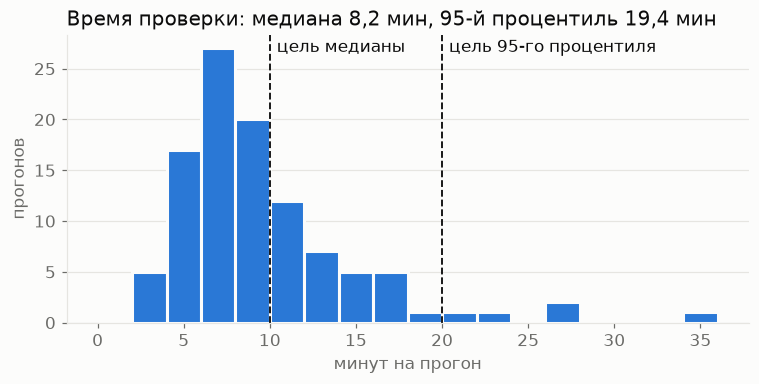

,значение
прогонов,104.0
"медиана, мин",8.2
"95-й процентиль, мин",19.4
"максимум, мин",35.1


In [11]:
minutes = new_runs["minutes"].dropna()
median, p95 = minutes.median(), minutes.quantile(0.95)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(minutes, bins=range(0, 38, 2), color=SERIES, edgecolor=SURFACE, linewidth=2)
for value, label, height in [
    (10, "цель медианы", 0.94),
    (20, "цель 95-го процентиля", 0.94),
]:
    ax.axvline(value, color=INK, linewidth=1.2, linestyle="--")
    ax.text(value + 0.4, ax.get_ylim()[1] * height, label, color=INK)
text = f"медиана {median:.1f} мин, 95-й процентиль {p95:.1f} мин".replace(".", ",")
ax.set_title(f"Время проверки: {text}")
ax.set_xlabel("минут на прогон")
ax.set_ylabel("прогонов")
ax.grid(axis="x", visible=False)
fig.savefig(FIG / "05_run_minutes.png", dpi=150, bbox_inches="tight")
plt.show()
pd.DataFrame(
    {
        "значение": [
            len(minutes),
            round(median, 1),
            round(p95, 1),
            round(minutes.max(), 1),
        ]
    },
    index=["прогонов", "медиана, мин", "95-й процентиль, мин", "максимум, мин"],
)

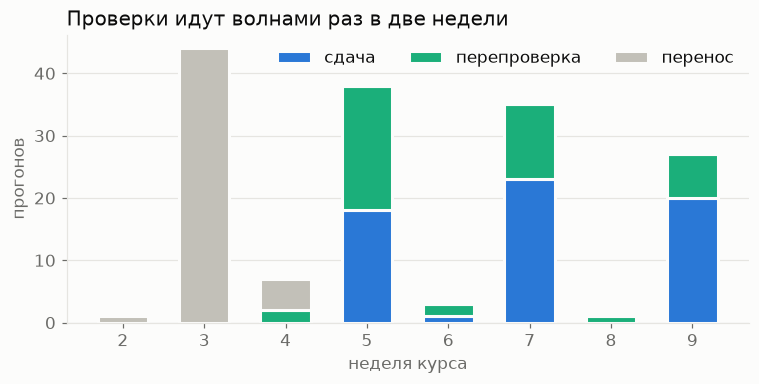

In [12]:
weekly = (
    runs.groupby(["week", "trigger"])
    .size()
    .unstack(fill_value=0)
    .reindex(range(2, 10), fill_value=0)
)
order = [
    ("submit", "сдача", SERIES),
    ("recheck", "перепроверка", "#1baf7a"),
    ("import", "перенос", "#c2c0b8"),
]
fig, ax = plt.subplots(figsize=(8, 3.4))
bottom = pd.Series(0, index=weekly.index)
for key, label, color in order:
    ax.bar(
        weekly.index,
        weekly[key],
        bottom=bottom,
        color=color,
        width=0.62,
        label=label,
        edgecolor=SURFACE,
        linewidth=2,
    )
    bottom = bottom + weekly[key]
ax.set_title("Проверки идут волнами раз в две недели")
ax.set_xlabel("неделя курса")
ax.set_ylabel("прогонов")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, ncols=3, loc="upper right")
fig.savefig(FIG / "06_runs_by_week.png", dpi=150, bbox_inches="tight")
plt.show()

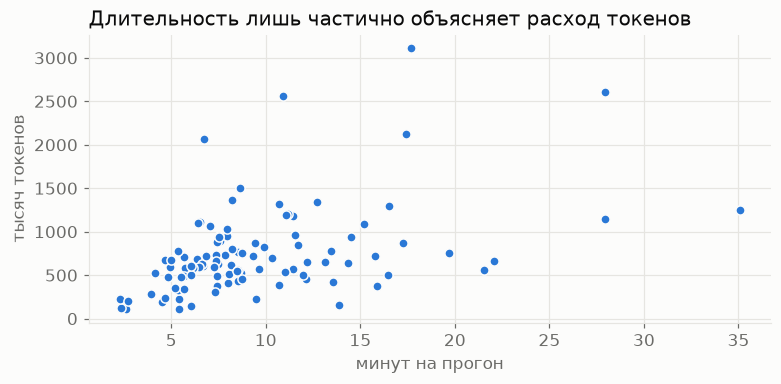

,значение
"токенов на прогон, медиана",647258.000
"токенов на прогон, 95-й процентиль",1481191.000
доля кэшированных входных токенов,0.811
корреляция Спирмена с минутами,0.450


In [13]:
usage = new_runs.dropna(subset=["tokens_in"]).assign(
    tokens=lambda d: d["tokens_in"] + d["tokens_out"]
)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.scatter(
    usage["minutes"],
    usage["tokens"] / 1000,
    s=36,
    color=SERIES,
    edgecolor=SURFACE,
    linewidth=1,
)
ax.set_title("Длительность лишь частично объясняет расход токенов")
ax.set_xlabel("минут на прогон")
ax.set_ylabel("тысяч токенов")
fig.savefig(FIG / "07_tokens_vs_minutes.png", dpi=150, bbox_inches="tight")
plt.show()
pd.DataFrame(
    {
        "значение": [
            int(usage["tokens"].median()),
            int(usage["tokens"].quantile(0.95)),
            round(usage["tokens_cached"].sum() / usage["tokens_in"].sum(), 3),
            round(usage["minutes"].rank().corr(usage["tokens"].rank()), 2),
        ]
    },
    index=[
        "токенов на прогон, медиана",
        "токенов на прогон, 95-й процентиль",
        "доля кэшированных входных токенов",
        "корреляция Спирмена с минутами",
    ],
)

**Вывод.** Медиана 8,2 минуты и 95-й процентиль 19,4 укладываются в ФТ-8, но 5 прогонов дольше 20 минут. Нагрузка идёт волнами: почти все проверки приходятся на недели 5, 7 и 9, до 38 прогонов в неделю, поэтому нагрузочный тест в ДЗ 4 надо строить на волне, а не на среднем. На прогон уходит около 650 тысяч токенов, 81% входных берутся из кэша. Связь токенов со временем умеренная (0,45), значит при сравнении версий надо смотреть на оба числа.

## 7. Приёмка и перепроверки

In [14]:
clean = reviews[reviews["minutes"] < 600]["minutes"]
pd.DataFrame(
    {
        "значение": [
            len(reviews),
            round(reviews["minutes"].median(), 1),
            round(clean.quantile(0.9), 1),
            len(reviews) - len(clean),
            int(reviews["by_hand"].sum()),
            int(rechecks["count"].sum()),
            int(rechecks.loc[rechecks["kind"] == "learner", "count"].sum()),
        ]
    },
    index=[
        "закрытых приёмок",
        "медиана, мин",
        "90-й процентиль без выбросов, мин",
        "выбросов таймера",
        "таймер поправлен вручную",
        "запросов на перепроверку",
        "из них от студентов",
    ],
)

,значение
закрытых приёмок,25.0
"медиана, мин",29.0
"90-й процентиль без выбросов, мин",42.4
выбросов таймера,1.0
таймер поправлен вручную,1.0
запросов на перепроверку,42.0
из них от студентов,38.0


**Вывод.** Типичная приёмка занимает 29 минут, но зависит не только от судьи, поэтому это наблюдаемая метрика, а не цель. Студенты сами запросили 38 перепроверок из 42: значит, вердиктами пользуются, и перепроверки стоит считать бизнес-метрикой.

## Итог

Что берём в работу:

1. **Эталон.** Около 150 вердиктов нового судьи, отобранных случайно с разбивкой по командам, работам и типам проверки, с запасом по трудным критериям.
2. **Деление данных.** По командам. Работу прошлого года проверим как отдельную отложенную часть, если подойдут критерии.
3. **Метрики.** Ошибки среди закрытых и ложные «не закрыт» отдельно, а не общая точность. Интервалы строим бутстрепом по командам.
4. **Повторы.** Несколько прогонов на одном коммите для настоящей повторяемости.
5. **Версии.** В платформе записывать хеш подсказок, иначе версии судьи не сравнить по истории.